# ANLP_4 - Topic Modeling with Latent Dirichlet Allocation
**Problem statement:** Apply LDA to a small collection of text documents and display the top five words associated with each discovered topic.

This notebook walks through every stage of `pipeline.py` and records its real outputs.

In [1]:
import pandas as pd
import pipeline as P
pd.set_option('display.max_colwidth', 120)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 1. Load the corpus
20 short synthetic news-style documents, 5 each about Sports, Finance, Health and Technology. The `true_theme` column is **never given to LDA** - it is only used afterwards to check the topics.

In [2]:
df = P.load_corpus(P.SAMPLE_CORPUS)
print(df['true_theme'].value_counts().to_dict())
df.head(6)

{'Sports': 5, 'Finance': 5, 'Health': 5, 'Technology': 5}


,doc_id,true_theme,text
0,D01,Sports,The cricket team won the final match after the captain scored a brilliant century. The bowlers took early wickets an...
1,D02,Sports,In the football league the striker scored two goals and the goalkeeper saved a penalty. The coach praised the player...
2,D03,Sports,"The tennis player won the tournament after a long match in the final set. Her coach said training, fitness and focus..."
3,D04,Sports,The national team selected three young players for the cricket series. The captain said the bowlers and batsmen trai...
4,D05,Sports,Fans filled the stadium for the derby match where the home team scored a late goal. The players and coach thanked th...
5,D06,Finance,The stock market rose today as investors bought shares of banking companies. The index gained two percent after the ...


## 2. Preprocessing
Lowercase -> keep alphabetic tokens of 3+ letters -> remove stopwords (scikit-learn list + a small custom list) -> merge plurals into singulars when the singular also occurs in the corpus.

In [3]:
cleaned, plural_map, tokens = P.preprocess(df['text'].tolist())
print('RAW    :', df['text'][0])
print('CLEANED:', cleaned[0])
print('\nPlural merges:', dict(sorted(plural_map.items())))

RAW    : The cricket team won the final match after the captain scored a brilliant century. The bowlers took early wickets and the fielders held every catch, so the team defended the total and the fans celebrated the victory in the stadium.
CLEANED: cricket team won final match captain scored brilliant century bowlers took wickets fielders held catch team defended total fans celebrated victory stadium

Plural merges: {'chips': 'chip', 'companies': 'company', 'doctors': 'doctor', 'dollars': 'dollar', 'goals': 'goal', 'kidneys': 'kidney', 'patients': 'patient', 'players': 'player', 'prices': 'price', 'shares': 'share', 'users': 'user'}


## 3. Document-term matrix (bag of words)
LDA models word **counts**, so `CountVectorizer` is used (not TF-IDF). `min_df=2` drops words seen in only one document; `max_df=0.5` drops words in more than half of them.

In [4]:
X, vectorizer = P.build_dtm(cleaned)
names = vectorizer.get_feature_names_out()
print('DTM shape (documents x words):', X.shape)
freq = pd.Series(X.sum(axis=0).A1, index=names).sort_values(ascending=False)
freq.head(15)

DTM shape (documents x words): (20, 71)


team         7
patient      7
company      7
software     5
model        5
player       5
market       5
investors    5
doctor       5
data         5
match        4
rates        4
share        4
stock        4
hospital     4
dtype: int64

## 4. Fit LDA
scikit-learn `LatentDirichletAllocation`, batch variational Bayes, K = 4. Fitted 10 times with different seeds; the run with the highest approximate log-likelihood (`lda.score(X)`) is kept - an unsupervised choice that does not look at the labels.

In [5]:
lda = P.fit_lda(X, n_topics=4, random_state=42, n_restarts=10)
print('Winning seed      :', lda.best_seed_)
print('Log-likelihood    :', round(lda.best_loglik_, 2))
print('EM iterations     :', lda.n_iter_)
print('Perplexity        :', round(lda.perplexity(X), 2))
print('components_ shape :', lda.components_.shape, '(topics x words)')

Winning seed      : 47
Log-likelihood    : -871.47
EM iterations     : 19
Perplexity        : 60.99
components_ shape : (4, 71) (topics x words)


## 5. Top five words per topic  *(main deliverable)*
Each row of `lda.components_` is normalised to P(word | topic); the 5 largest values are the top words.

In [6]:
top = P.top_words(lda, names, n=5)
for t, grp in top.groupby('topic'):
    words = ', '.join(f"{w} ({p:.3f})" for w, p in zip(grp['word'], grp['weight']))
    print(f'Topic {t + 1}: {words}')

Topic 1: model (0.069), software (0.069), data (0.056), user (0.056), trained (0.043)
Topic 2: patient (0.102), doctor (0.074), hospital (0.060), heart (0.046), diet (0.046)
Topic 3: team (0.107), player (0.077), match (0.063), coach (0.063), fans (0.048)
Topic 4: market (0.076), investors (0.076), company (0.062), stock (0.062), share (0.062)


In [7]:
P.top_words_wide(top)

,topic,top_words
0,Topic 1,"model, software, data, user, trained"
1,Topic 2,"patient, doctor, hospital, heart, diet"
2,Topic 3,"team, player, match, coach, fans"
3,Topic 4,"market, investors, company, stock, share"


## 6. Document-topic mixture
`lda.transform(X)` gives P(topic | document). The dominant topic is the largest entry.

In [8]:
dt = P.doc_topic_table(lda, X, df['doc_id'])
dt.assign(true_theme=df['true_theme']).round(3)

,doc_id,Topic 1,Topic 2,Topic 3,Topic 4,dominant_topic,dominant_prob,true_theme
0,D01,0.019,0.019,0.942,0.019,3,0.942,Sports
1,D02,0.028,0.028,0.916,0.028,3,0.916,Sports
2,D03,0.025,0.025,0.925,0.025,3,0.925,Sports
3,D04,0.029,0.028,0.916,0.028,3,0.916,Sports
4,D05,0.018,0.018,0.946,0.018,3,0.946,Sports
5,D06,0.018,0.018,0.018,0.946,4,0.946,Finance
6,D07,0.018,0.018,0.018,0.946,4,0.946,Finance
7,D08,0.028,0.028,0.028,0.916,4,0.916,Finance
8,D09,0.023,0.023,0.023,0.932,4,0.932,Finance
9,D10,0.031,0.031,0.031,0.906,4,0.906,Finance


## 7. Evaluation
### 7.1 UMass coherence (from the corpus itself, higher / closer to 0 = better)

In [9]:
P.umass_coherence(X, top, vectorizer).round(3)

,topic,umass
0,Topic 1,-0.101
1,Topic 2,-0.186
2,Topic 3,-0.174
3,Topic 4,-0.087


### 7.2 Agreement with the known themes

In [10]:
agr = P.theme_agreement(dt, df['true_theme'])
labels = P.label_topics(dt, df['true_theme'])
print({f'Topic {k}': v for k, v in labels.items()})
print(f"Purity {agr['purity']:.3f} | NMI {agr['nmi']:.3f} | ARI {agr['ari']:.3f}")
agr['contingency']

{'Topic 1': 'Technology', 'Topic 2': 'Health', 'Topic 3': 'Sports', 'Topic 4': 'Finance'}
Purity 1.000 | NMI 1.000 | ARI 1.000


theme,Finance,Health,Sports,Technology
topic,,,,
1,0,0,0,5
2,0,5,0,0
3,0,0,5,0
4,5,0,0,0


### 7.3 Choosing K
Perplexity here is measured on the training documents (the corpus is too small to hold data out).

In [11]:
sweep = P.k_sweep(X, vectorizer, ks=range(2, 7), true_themes=df['true_theme'])
sweep.round(3)

,k,perplexity,mean_umass,purity
0,2,74.360,-0.750,0.50
1,3,69.053,-0.312,0.75
2,4,60.989,-0.137,1.00
3,5,64.765,-0.023,1.00
4,6,68.918,0.001,1.00


### 7.4 Why restarts? Seed stability

In [12]:
stab = P.seed_stability(X, 4, df['true_theme'])
print(stab.iloc[:, 1:].mean().round(3).to_dict())
stab

{'purity_single_run': 0.805, 'purity_best_of_10': 1.0}


,seed,purity_single_run,purity_best_of_10
0,0,0.75,1.0
1,1,1.00,1.0
2,2,0.50,1.0
3,3,1.00,1.0
4,4,0.75,1.0
5,5,0.75,1.0
6,6,0.85,1.0
7,7,0.80,1.0
8,8,0.75,1.0
9,9,0.90,1.0


## 8. Save outputs (CSV + figures) to `outputs/`

In [13]:
res = P.run_pipeline(df['text'].tolist(), n_topics=4, doc_ids=df['doc_id'], true_themes=df['true_theme'])
saved = P.save_outputs(res, sweep=sweep, stability=stab)
[p.name for p in saved]

['topics_top5.csv',
 'topic_word_weights.csv',
 'doc_topic_distribution.csv',
 'topic_coherence.csv',
 'model_selection.csv',
 'seed_stability.csv',
 'topic_top_words.png',
 'doc_topic_heatmap.png',
 'model_selection.png',
 'summary.json']

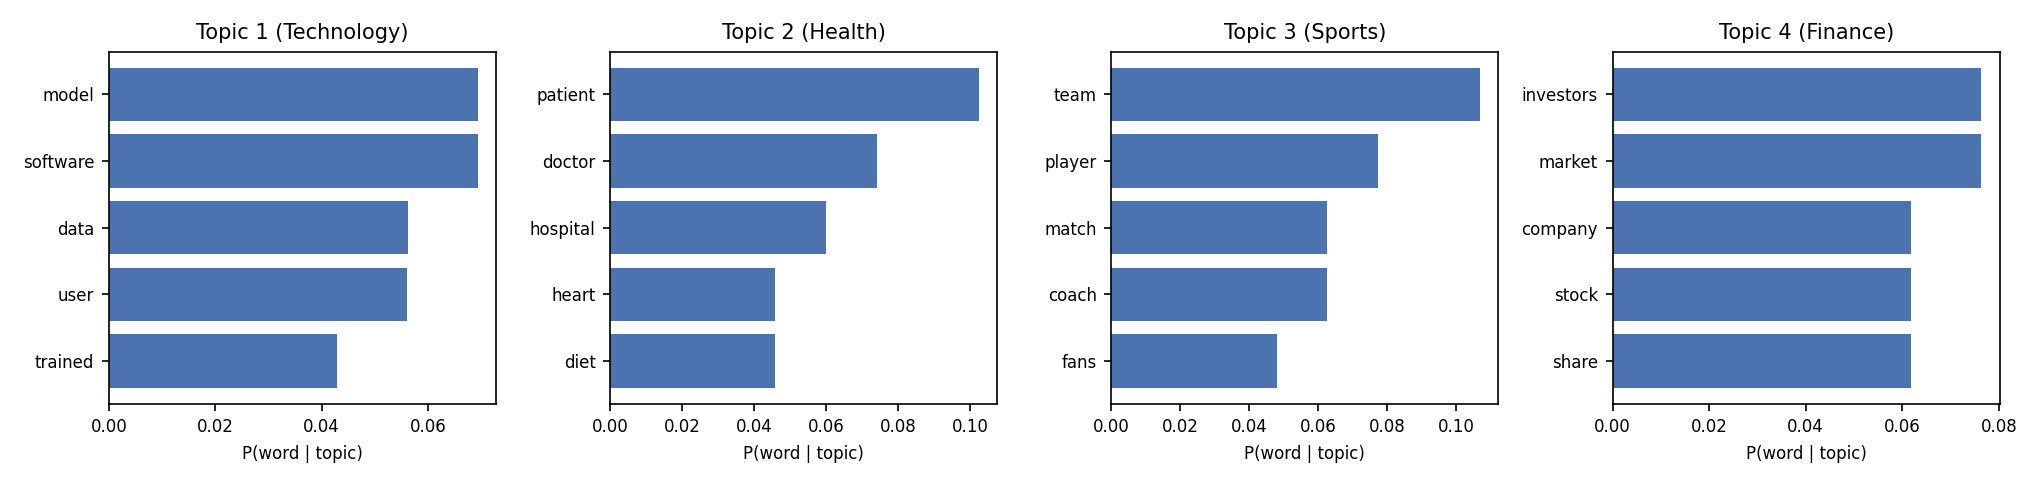

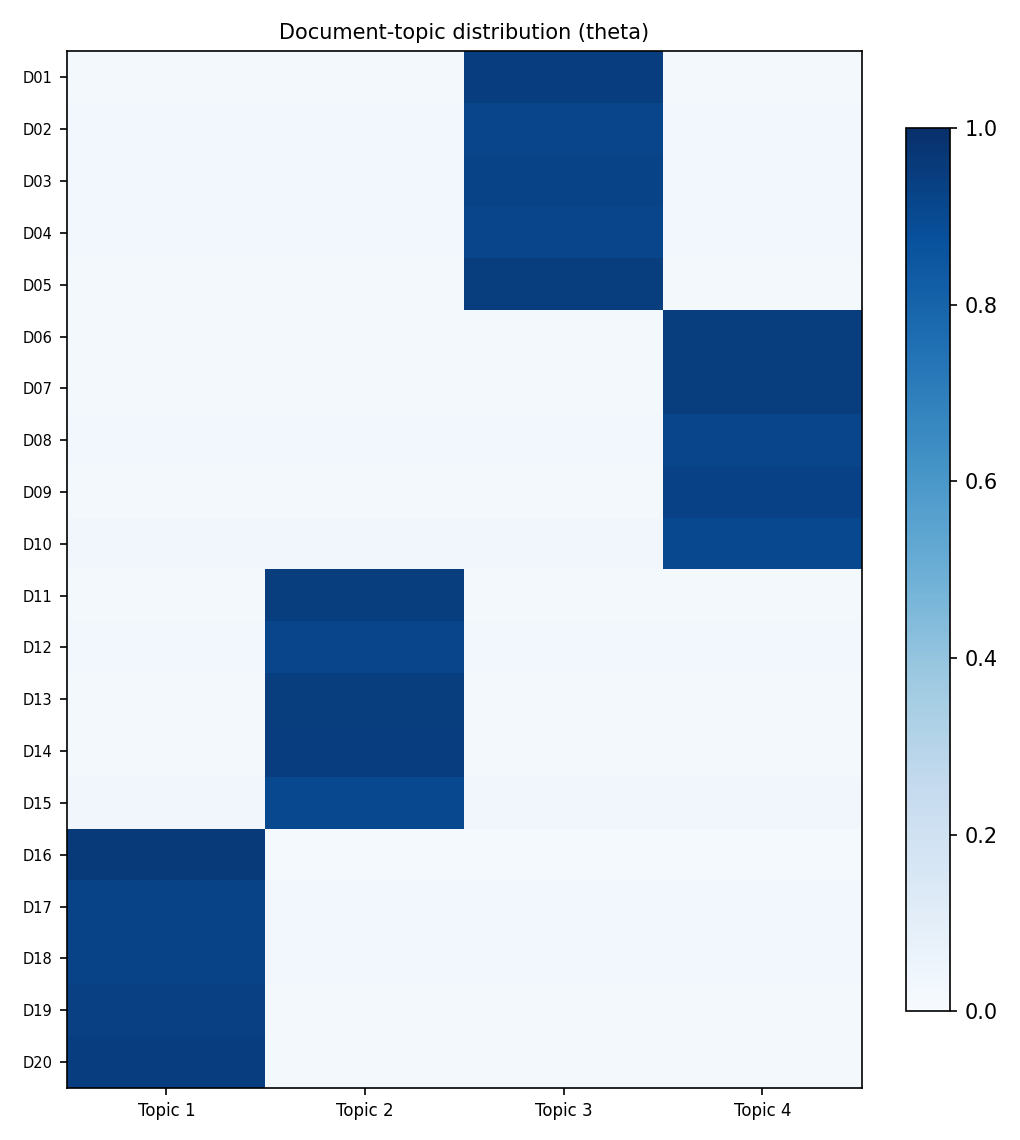

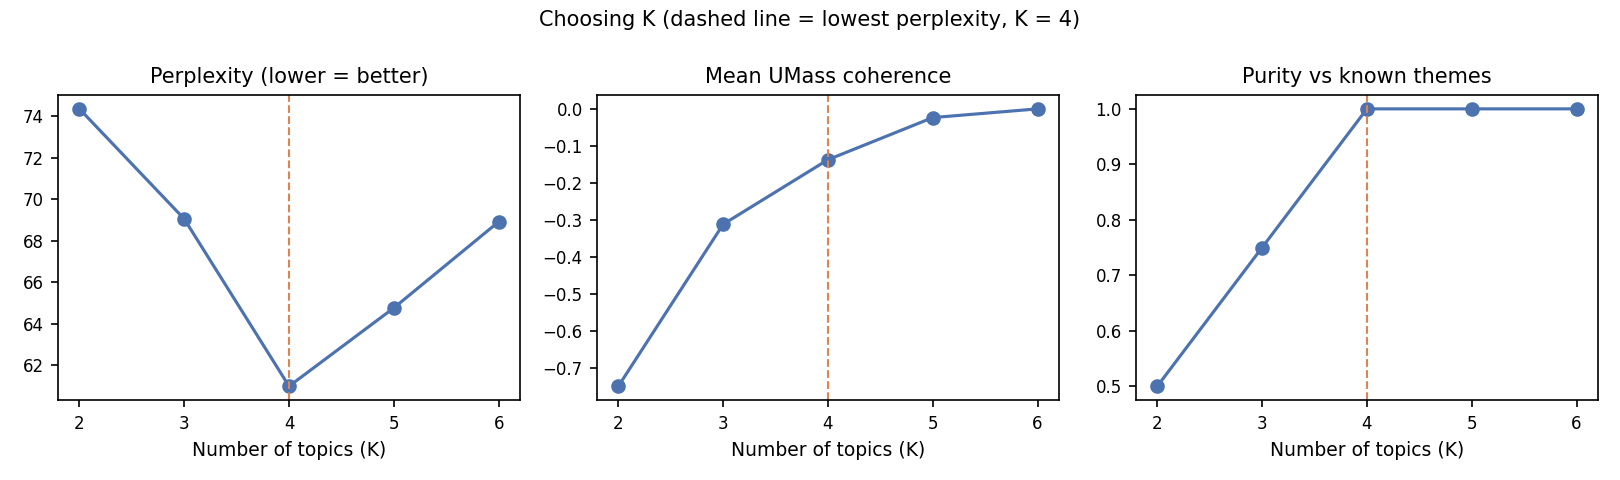

In [14]:
from IPython.display import Image, display
for f in ['topic_top_words.png', 'doc_topic_heatmap.png', 'model_selection.png']:
    display(Image(filename=str(P.OUTPUT_DIR / f)))